# Analysis of Serve Direction (ATP 2010 - 2025)

**Author:** Galiya Galimova | Tennis Analyst

**Period:** 2010–2025  

**Data:** 2010-2025 Match Charting Project (source: Jeff Sackmann's Match Charting Project [github](https://github.com/JeffSackmann/tennis_MatchChartingProject))

---

### Executive Summary

**Objective:** To classify tennis players based on their serve direction preferences on different sides of the court (deuce vs ad) and to identify distinct serve tactics and playing styles.

**Method:** Cluster Analysis

**Metrics:**
- Serve: number of wide serves on deuce side, number of middle serves on deuce side, number of t serves on deuce side, number of wide serves on ad side, number of middle serves on ad side, number of t serves on ad side
- Errors: number of errors into the net, number of of wide serve errors, number of deep serve errors, number of wide and deep serve errors, number of foot faults

**Key Insights:**
- 4 features were selected for cluster analysis: percentage of wide serve and percentage of T serve on the deuce side and percentage of wide serve and percentage of T serve on the ad side. These features better define a player's tactics and aggressiveness.
  
Based on the analysis, two clusters were identified:
- **Cluster 0**: Strong asymmetry between sides. T-serve (46%) dominates on the deuce side (attacking the backhand) while wide serve (55%) dominates on the ad side (pushing the opponent off the court).
- **Cluster 1**: Almost symmetric play on both sides. Moderate preference for wide serves on the deuce and ad sides (41% and 40% respectively).

### Import the data

In [1]:
#Import libraries
import numpy as np 
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt
%matplotlib inline 

import warnings
warnings.filterwarnings('ignore')

In [2]:
#Display all columns and rows
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [3]:
#Import the data
stats_serve = pd.read_csv('charting-m-stats-ServeDirection.csv')
stats_serve.head()

,match_id,player,row,deuce_wide,deuce_middle,deuce_t,ad_wide,ad_middle,ad_t,err_net,err_wide,err_deep,err_wide_deep,err_foot,err_unknown
0,20251221-M-NextGen_Finals-F-Alexander_Blockx-L...,Alexander Blockx,Total,15,2,10,10,4,7,4,2,5,0,0,0
1,20251221-M-NextGen_Finals-F-Alexander_Blockx-L...,Alexander Blockx,1,11,1,10,9,3,4,0,0,0,0,0,0
2,20251221-M-NextGen_Finals-F-Alexander_Blockx-L...,Alexander Blockx,2,4,1,0,1,1,3,4,2,5,0,0,0
3,20251221-M-NextGen_Finals-F-Alexander_Blockx-L...,Learner Tien,Total,10,4,13,16,0,9,7,3,7,2,0,0
4,20251221-M-NextGen_Finals-F-Alexander_Blockx-L...,Learner Tien,1,9,2,5,10,0,8,0,0,0,0,0,0


In [4]:
#Display information about a dataframe including the index dtype and columns, non-NA values and memory usage
stats_serve.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43109 entries, 0 to 43108
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   match_id       43109 non-null  object
 1   player         43109 non-null  object
 2   row            43109 non-null  object
 3   deuce_wide     43109 non-null  int64 
 4   deuce_middle   43109 non-null  int64 
 5   deuce_t        43109 non-null  int64 
 6   ad_wide        43109 non-null  int64 
 7   ad_middle      43109 non-null  int64 
 8   ad_t           43109 non-null  int64 
 9   err_net        43109 non-null  int64 
 10  err_wide       43109 non-null  int64 
 11  err_deep       43109 non-null  int64 
 12  err_wide_deep  43109 non-null  int64 
 13  err_foot       43109 non-null  int64 
 14  err_unknown    43109 non-null  int64 
dtypes: int64(12), object(3)
memory usage: 4.9+ MB


In [5]:
#Split the 'match_id' variable into parts
split_data = stats_serve['match_id'].str.split('-', expand=True)

#Create the 'date' variable
stats_serve['date'] = split_data[0]
stats_serve['date'] = pd.to_datetime(stats_serve.date, format = '%Y%m%d')
stats_serve.head()

,match_id,player,row,deuce_wide,deuce_middle,deuce_t,ad_wide,ad_middle,ad_t,err_net,err_wide,err_deep,err_wide_deep,err_foot,err_unknown,date
0,20251221-M-NextGen_Finals-F-Alexander_Blockx-L...,Alexander Blockx,Total,15,2,10,10,4,7,4,2,5,0,0,0,2025-12-21
1,20251221-M-NextGen_Finals-F-Alexander_Blockx-L...,Alexander Blockx,1,11,1,10,9,3,4,0,0,0,0,0,0,2025-12-21
2,20251221-M-NextGen_Finals-F-Alexander_Blockx-L...,Alexander Blockx,2,4,1,0,1,1,3,4,2,5,0,0,0,2025-12-21
3,20251221-M-NextGen_Finals-F-Alexander_Blockx-L...,Learner Tien,Total,10,4,13,16,0,9,7,3,7,2,0,0,2025-12-21
4,20251221-M-NextGen_Finals-F-Alexander_Blockx-L...,Learner Tien,1,9,2,5,10,0,8,0,0,0,0,0,0,2025-12-21


### Create a filtered dataset for analysis

In [6]:
#Filter data to include only relevant matches and aggregated statistics
stats_serve_present = stats_serve[(stats_serve['date'] >= '2010') & (stats_serve['row'] == 'Total')]
stats_serve_present.head()

,match_id,player,row,deuce_wide,deuce_middle,deuce_t,ad_wide,ad_middle,ad_t,err_net,err_wide,err_deep,err_wide_deep,err_foot,err_unknown,date
0,20251221-M-NextGen_Finals-F-Alexander_Blockx-L...,Alexander Blockx,Total,15,2,10,10,4,7,4,2,5,0,0,0,2025-12-21
3,20251221-M-NextGen_Finals-F-Alexander_Blockx-L...,Learner Tien,Total,10,4,13,16,0,9,7,3,7,2,0,0,2025-12-21
6,20251219-M-NextGen_Finals-RR-Nishesh_Basavared...,Nishesh Basavareddy,Total,20,4,7,14,4,6,8,9,8,2,0,0,2025-12-19
9,20251219-M-NextGen_Finals-RR-Nishesh_Basavared...,Justin Engel,Total,10,12,10,22,2,5,7,4,7,0,0,0,2025-12-19
12,20251217-M-NextGen_Finals-RR-Rafael_Jodar-Lear...,Rafael Jodar,Total,16,9,26,15,9,20,8,2,21,2,0,0,2025-12-17


In [7]:
#Display information about a dataframe after filtering the data
stats_serve_present.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10660 entries, 0 to 31976
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   match_id       10660 non-null  object        
 1   player         10660 non-null  object        
 2   row            10660 non-null  object        
 3   deuce_wide     10660 non-null  int64         
 4   deuce_middle   10660 non-null  int64         
 5   deuce_t        10660 non-null  int64         
 6   ad_wide        10660 non-null  int64         
 7   ad_middle      10660 non-null  int64         
 8   ad_t           10660 non-null  int64         
 9   err_net        10660 non-null  int64         
 10  err_wide       10660 non-null  int64         
 11  err_deep       10660 non-null  int64         
 12  err_wide_deep  10660 non-null  int64         
 13  err_foot       10660 non-null  int64         
 14  err_unknown    10660 non-null  int64         
 15  date           10660 non

In [8]:
#Generate descriptive statistics including number of values, mean, standard deviation
stats_serve_present.describe()

,deuce_wide,deuce_middle,deuce_t,ad_wide,ad_middle,ad_t,err_net,err_wide,err_deep,err_wide_deep,err_foot,err_unknown,date
count,10660.000000,10660.00000,10660.000000,10660.000000,10660.000000,10660.000000,10660.000000,10660.000000,10660.000000,10660.000000,10660.000000,10660.000000,10660
mean,16.128893,8.90122,17.289118,18.408537,7.486679,12.658443,13.593058,6.396529,11.078893,1.745779,0.045028,0.047561,2020-07-06 20:43:51.444652800
min,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2010-01-08 00:00:00
25%,10.000000,4.00000,11.000000,12.000000,3.000000,8.000000,8.000000,4.000000,7.000000,0.000000,0.000000,0.000000,2017-10-20 00:00:00
50%,14.000000,8.00000,16.000000,17.000000,6.000000,11.000000,12.000000,6.000000,10.000000,1.000000,0.000000,0.000000,2021-10-13 00:00:00
75%,20.000000,12.00000,22.000000,23.000000,10.000000,16.000000,17.000000,8.000000,14.000000,3.000000,0.000000,0.000000,2024-01-01 00:00:00
max,116.000000,55.00000,121.000000,118.000000,58.000000,96.000000,65.000000,58.000000,65.000000,17.000000,9.000000,9.000000,2025-12-21 00:00:00
std,8.605263,6.75210,9.033732,9.332562,6.070381,7.448566,7.293691,4.021367,6.184991,1.947405,0.312720,0.323992,NaN


**Conclusion:** We have the data for the period from 2010 to 2025. The dataset contains 10660 rows.

### Calculate percentages of different types of serve across both sides

In [9]:
#Calculate total number of serves on deuce and ad sides
stats_serve_present['deuce_total'] = stats_serve_present['deuce_wide'] + stats_serve_present['deuce_middle'] + \
                                     stats_serve_present['deuce_t']
stats_serve_present['ad_total'] = stats_serve_present['ad_wide'] + stats_serve_present['ad_middle'] + stats_serve_present['ad_t']

In [10]:
#Calculate deuce side percentages (wide, middle, t)
stats_serve_present['deuce_wide_pct'] = (stats_serve_present['deuce_wide'] / stats_serve_present['deuce_total']).round(2)
stats_serve_present['deuce_middle_pct'] = (stats_serve_present['deuce_middle'] / stats_serve_present['deuce_total']).round(2)
stats_serve_present['deuce_t_pct'] = (stats_serve_present['deuce_t'] / stats_serve_present['deuce_total']).round(2)

#Calculate ad side percentages (wide, middle, t)
stats_serve_present['ad_wide_pct'] = (stats_serve_present['ad_wide'] / stats_serve_present['ad_total']).round(2)
stats_serve_present['ad_middle_pct'] = (stats_serve_present['ad_middle'] / stats_serve_present['ad_total']).round(2)
stats_serve_present['ad_t_pct'] = (stats_serve_present['ad_t'] / stats_serve_present['ad_total']).round(2)

#Calculate overall percentages across both sides
stats_serve_present['wide_pct'] = ((stats_serve_present['deuce_wide'] + stats_serve_present['ad_wide'])/(stats_serve_present['deuce_total'] + \
                                  stats_serve_present['ad_total'])).round(2)
stats_serve_present['middle_pct'] = ((stats_serve_present['deuce_middle'] + stats_serve_present['ad_middle'])/(stats_serve_present['deuce_total'] + \
                                  stats_serve_present['ad_total'])).round(2)
stats_serve_present['t_pct'] = ((stats_serve_present['deuce_t'] + stats_serve_present['ad_t'])/(stats_serve_present['deuce_total'] + \
                                  stats_serve_present['ad_total'])).round(2)
                                                
stats_serve_present.head()

,match_id,player,row,deuce_wide,deuce_middle,deuce_t,ad_wide,ad_middle,ad_t,err_net,err_wide,err_deep,err_wide_deep,err_foot,err_unknown,date,deuce_total,ad_total,deuce_wide_pct,deuce_middle_pct,deuce_t_pct,ad_wide_pct,ad_middle_pct,ad_t_pct,wide_pct,middle_pct,t_pct
0,20251221-M-NextGen_Finals-F-Alexander_Blockx-L...,Alexander Blockx,Total,15,2,10,10,4,7,4,2,5,0,0,0,2025-12-21,27,21,0.56,0.07,0.37,0.48,0.19,0.33,0.52,0.12,0.35
3,20251221-M-NextGen_Finals-F-Alexander_Blockx-L...,Learner Tien,Total,10,4,13,16,0,9,7,3,7,2,0,0,2025-12-21,27,25,0.37,0.15,0.48,0.64,0.00,0.36,0.50,0.08,0.42
6,20251219-M-NextGen_Finals-RR-Nishesh_Basavared...,Nishesh Basavareddy,Total,20,4,7,14,4,6,8,9,8,2,0,0,2025-12-19,31,24,0.65,0.13,0.23,0.58,0.17,0.25,0.62,0.15,0.24
9,20251219-M-NextGen_Finals-RR-Nishesh_Basavared...,Justin Engel,Total,10,12,10,22,2,5,7,4,7,0,0,0,2025-12-19,32,29,0.31,0.38,0.31,0.76,0.07,0.17,0.52,0.23,0.25
12,20251217-M-NextGen_Finals-RR-Rafael_Jodar-Lear...,Rafael Jodar,Total,16,9,26,15,9,20,8,2,21,2,0,0,2025-12-17,51,44,0.31,0.18,0.51,0.34,0.20,0.45,0.33,0.19,0.48


In [11]:
#Calculate total number of errors on serve
stats_serve_present['err_total'] = stats_serve_present['err_net'] + stats_serve_present['err_wide'] + stats_serve_present['err_deep'] + \
                                   stats_serve_present['err_wide_deep'] + stats_serve_present['err_foot'] + stats_serve_present['err_unknown']

#Calculate percentages of errors on serve
stats_serve_present['err_net_pct'] = (stats_serve_present['err_net'] / stats_serve_present['err_total']).round(2)
stats_serve_present['err_wide_pct'] = (stats_serve_present['err_wide'] / stats_serve_present['err_total']).round(2)
stats_serve_present['err_deep_pct'] = (stats_serve_present['err_deep'] / stats_serve_present['err_total']).round(2)
stats_serve_present['err_wide_deep_pct'] = (stats_serve_present['err_wide_deep'] / stats_serve_present['err_total']).round(2)
stats_serve_present['err_foot_pct'] = (stats_serve_present['err_foot'] / stats_serve_present['err_total']).round(2)
stats_serve_present['err_unknown_pct'] = (stats_serve_present['err_unknown'] / stats_serve_present['err_total']).round(2)

stats_serve_present.head()

,match_id,player,row,deuce_wide,deuce_middle,deuce_t,ad_wide,ad_middle,ad_t,err_net,err_wide,err_deep,err_wide_deep,err_foot,err_unknown,date,deuce_total,ad_total,deuce_wide_pct,deuce_middle_pct,deuce_t_pct,ad_wide_pct,ad_middle_pct,ad_t_pct,wide_pct,middle_pct,t_pct,err_total,err_net_pct,err_wide_pct,err_deep_pct,err_wide_deep_pct,err_foot_pct,err_unknown_pct
0,20251221-M-NextGen_Finals-F-Alexander_Blockx-L...,Alexander Blockx,Total,15,2,10,10,4,7,4,2,5,0,0,0,2025-12-21,27,21,0.56,0.07,0.37,0.48,0.19,0.33,0.52,0.12,0.35,11,0.36,0.18,0.45,0.00,0.0,0.0
3,20251221-M-NextGen_Finals-F-Alexander_Blockx-L...,Learner Tien,Total,10,4,13,16,0,9,7,3,7,2,0,0,2025-12-21,27,25,0.37,0.15,0.48,0.64,0.00,0.36,0.50,0.08,0.42,19,0.37,0.16,0.37,0.11,0.0,0.0
6,20251219-M-NextGen_Finals-RR-Nishesh_Basavared...,Nishesh Basavareddy,Total,20,4,7,14,4,6,8,9,8,2,0,0,2025-12-19,31,24,0.65,0.13,0.23,0.58,0.17,0.25,0.62,0.15,0.24,27,0.30,0.33,0.30,0.07,0.0,0.0
9,20251219-M-NextGen_Finals-RR-Nishesh_Basavared...,Justin Engel,Total,10,12,10,22,2,5,7,4,7,0,0,0,2025-12-19,32,29,0.31,0.38,0.31,0.76,0.07,0.17,0.52,0.23,0.25,18,0.39,0.22,0.39,0.00,0.0,0.0
12,20251217-M-NextGen_Finals-RR-Rafael_Jodar-Lear...,Rafael Jodar,Total,16,9,26,15,9,20,8,2,21,2,0,0,2025-12-17,51,44,0.31,0.18,0.51,0.34,0.20,0.45,0.33,0.19,0.48,33,0.24,0.06,0.64,0.06,0.0,0.0


In [12]:
#Check number of missing values in the entire dataframe
stats_serve_present.isna().sum()

match_id             0
player               0
row                  0
deuce_wide           0
deuce_middle         0
deuce_t              0
ad_wide              0
ad_middle            0
ad_t                 0
err_net              0
err_wide             0
err_deep             0
err_wide_deep        0
err_foot             0
err_unknown          0
date                 0
deuce_total          0
ad_total             0
deuce_wide_pct       0
deuce_middle_pct     0
deuce_t_pct          0
ad_wide_pct          0
ad_middle_pct        0
ad_t_pct             0
wide_pct             0
middle_pct           0
t_pct                0
err_total            0
err_net_pct          1
err_wide_pct         1
err_deep_pct         1
err_wide_deep_pct    1
err_foot_pct         1
err_unknown_pct      1
dtype: int64

In [13]:
#Fill missing values in the dataframe with 0 because one of the tennis players retired
stats_serve_present = stats_serve_present.fillna(0).round(2)

In [14]:
#Aggregate serve statistics by player and calculate mean percentages and total serve counts
stats_by_player = stats_serve_present.groupby('player').agg({
    'deuce_wide_pct': 'mean',
    'deuce_middle_pct': 'mean',
    'deuce_t_pct': 'mean',
    'ad_wide_pct': 'mean',
    'ad_middle_pct': 'mean',
    'ad_t_pct': 'mean',
    'deuce_total': 'sum',
    'ad_total': 'sum',
    'err_net_pct': 'mean',
    'err_wide_pct': 'mean',
    'err_deep_pct': 'mean',
    'err_wide_deep_pct': 'mean',
    'err_foot_pct': 'mean',
    'err_unknown_pct': 'mean',
    'err_total': 'sum'
}).round(2).reset_index()

stats_by_player.head()

,player,deuce_wide_pct,deuce_middle_pct,deuce_t_pct,ad_wide_pct,ad_middle_pct,ad_t_pct,deuce_total,ad_total,err_net_pct,err_wide_pct,err_deep_pct,err_wide_deep_pct,err_foot_pct,err_unknown_pct,err_total
0,Abedallah Shelbayh,0.23,0.36,0.42,0.68,0.12,0.19,79,68,0.54,0.14,0.32,0.00,0.0,0.0,64
1,Adam Pavlasek,0.26,0.24,0.50,0.58,0.11,0.31,97,91,0.32,0.22,0.36,0.10,0.0,0.0,91
2,Adam Walton,0.46,0.12,0.43,0.44,0.15,0.42,95,82,0.47,0.18,0.30,0.06,0.0,0.0,74
3,Adrian Andreev,0.53,0.06,0.42,0.46,0.17,0.37,312,289,0.52,0.12,0.26,0.10,0.0,0.0,235
4,Adrian Mannarino,0.31,0.22,0.48,0.63,0.17,0.20,2824,2574,0.47,0.20,0.28,0.04,0.0,0.0,2289


In [15]:
#Display information about a new dataframe
stats_by_player.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 690 entries, 0 to 689
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   player             690 non-null    object 
 1   deuce_wide_pct     690 non-null    float64
 2   deuce_middle_pct   690 non-null    float64
 3   deuce_t_pct        690 non-null    float64
 4   ad_wide_pct        690 non-null    float64
 5   ad_middle_pct      690 non-null    float64
 6   ad_t_pct           690 non-null    float64
 7   deuce_total        690 non-null    int64  
 8   ad_total           690 non-null    int64  
 9   err_net_pct        690 non-null    float64
 10  err_wide_pct       690 non-null    float64
 11  err_deep_pct       690 non-null    float64
 12  err_wide_deep_pct  690 non-null    float64
 13  err_foot_pct       690 non-null    float64
 14  err_unknown_pct    690 non-null    float64
 15  err_total          690 non-null    int64  
dtypes: float64(12), int64(3), 

**Conclusion:** After player-level aggregation the dataset contains 690 tennis players with calculated average wide, middle and t serve percentages on deuce and ad court sides.

### Import tennis players' hand data

In [16]:
#Import the data from local directory
player_hand = pd.read_csv('player_hand.csv')
player_hand.head()

#Merge two dataframes
stats_by_player_all = pd.merge(stats_by_player, player_hand, on = 'player')
stats_by_player_all.head()

,player,deuce_wide_pct,deuce_middle_pct,deuce_t_pct,ad_wide_pct,ad_middle_pct,ad_t_pct,deuce_total,ad_total,err_net_pct,err_wide_pct,err_deep_pct,err_wide_deep_pct,err_foot_pct,err_unknown_pct,err_total,hand
0,Abedallah Shelbayh,0.23,0.36,0.42,0.68,0.12,0.19,79,68,0.54,0.14,0.32,0.00,0.0,0.0,64,L
1,Adam Pavlasek,0.26,0.24,0.50,0.58,0.11,0.31,97,91,0.32,0.22,0.36,0.10,0.0,0.0,91,R
2,Adam Walton,0.46,0.12,0.43,0.44,0.15,0.42,95,82,0.47,0.18,0.30,0.06,0.0,0.0,74,R
3,Adrian Andreev,0.53,0.06,0.42,0.46,0.17,0.37,312,289,0.52,0.12,0.26,0.10,0.0,0.0,235,R
4,Adrian Mannarino,0.31,0.22,0.48,0.63,0.17,0.20,2824,2574,0.47,0.20,0.28,0.04,0.0,0.0,2289,L


### Build cluster analysis

In [17]:
#Import standard scaler and kmeans method for cluster analysis
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [18]:
#Create working copy for clustering
clustering_data_all = stats_by_player_all.copy()

#Choose features for clustering 
features = ['deuce_wide_pct', 'deuce_t_pct', 'ad_wide_pct', 'ad_t_pct']

#Keep only relevant columns
clustering_data_all = clustering_data_all[features]

**Conclusion**: Two serve types on the deuce and ad sides (wide serve and T serve) were chosen for cluster analysis because they capture aggressiveness and tactics better and help define tennis players' playing style.

In [19]:
#Scale the data
scaler = StandardScaler()
scaled_data_all = scaler.fit_transform(clustering_data_all)

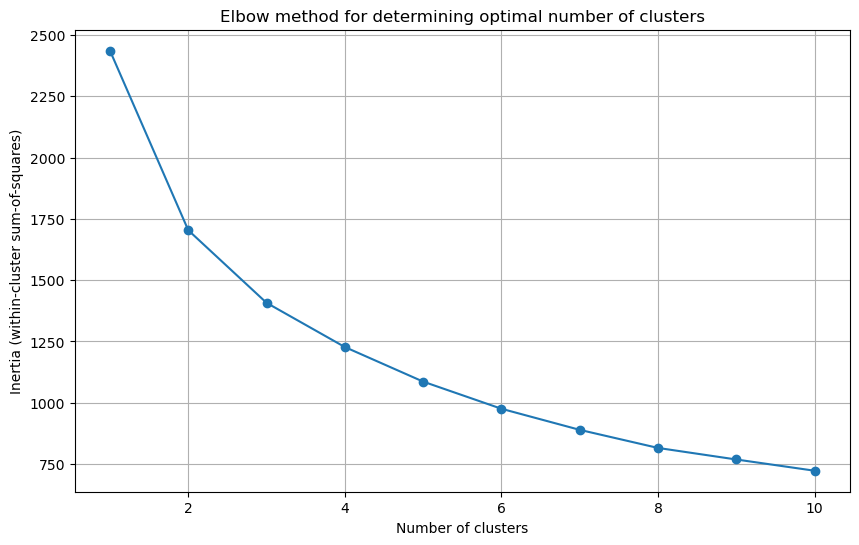

In [20]:
#Run elbow method for determing number of clusters
inertia = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters = k, random_state = 42, n_init = 10)
    kmeans.fit(scaled_data_all)
    inertia.append(kmeans.inertia_)

plt.figure(figsize = (10, 6))
plt.plot(range(1, 11), inertia, marker = 'o')
plt.title('Elbow method for determining optimal number of clusters')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia (within-cluster sum-of-squares)')
plt.grid(True)
plt.show()

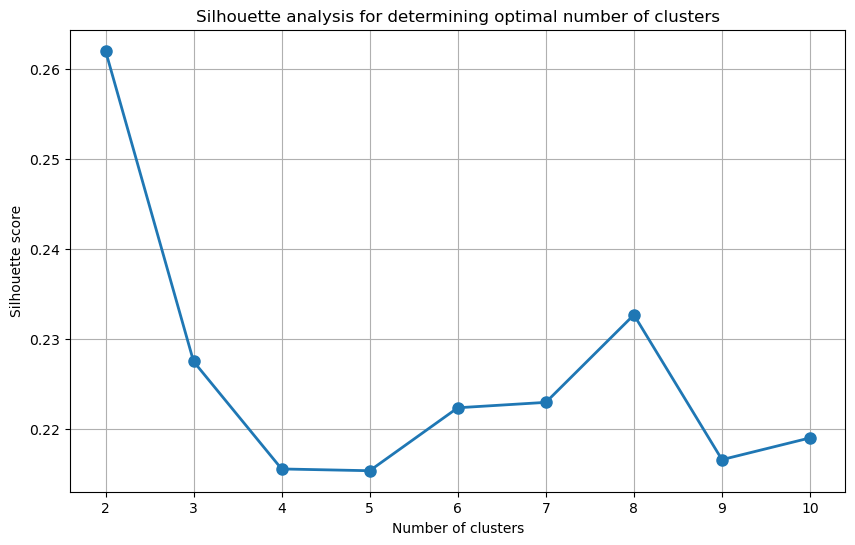

In [21]:
#Import silhouette score
from sklearn.metrics import silhouette_score

#Run silhouette method for determing number of clusters
silhouette_scores = []
k_range = range(2, 11)
for k in k_range:
    kmeans = KMeans(n_clusters = k, random_state = 42, n_init = 10) 
    labels = kmeans.fit_predict(scaled_data_all)  
    score = silhouette_score(scaled_data_all, labels)  
    silhouette_scores.append(score)
 
plt.figure(figsize = (10, 6))
plt.plot(range(2, 11), silhouette_scores, marker = 'o', linewidth = 2, markersize = 8)
plt.title('Silhouette analysis for determining optimal number of clusters')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette score')
plt.grid(True)
plt.show()

**Conclusion**: The elbow and silhouette methods identified 2 clusters for subsequent analysis.

In [22]:
#Run cluster analysis
kmeans = KMeans(n_clusters = 2, random_state = 42, n_init = 10)
kmeans_labels_all = kmeans.fit_predict(scaled_data_all)

#Add cluster labels to the 'stats_by_player_all' dataframe
stats_by_player_all['cluster'] = kmeans_labels_all

## Display the dataframe with new column 'cluster'
stats_by_player_all.head()

,player,deuce_wide_pct,deuce_middle_pct,deuce_t_pct,ad_wide_pct,ad_middle_pct,ad_t_pct,deuce_total,ad_total,err_net_pct,err_wide_pct,err_deep_pct,err_wide_deep_pct,err_foot_pct,err_unknown_pct,err_total,hand,cluster
0,Abedallah Shelbayh,0.23,0.36,0.42,0.68,0.12,0.19,79,68,0.54,0.14,0.32,0.00,0.0,0.0,64,L,0
1,Adam Pavlasek,0.26,0.24,0.50,0.58,0.11,0.31,97,91,0.32,0.22,0.36,0.10,0.0,0.0,91,R,0
2,Adam Walton,0.46,0.12,0.43,0.44,0.15,0.42,95,82,0.47,0.18,0.30,0.06,0.0,0.0,74,R,1
3,Adrian Andreev,0.53,0.06,0.42,0.46,0.17,0.37,312,289,0.52,0.12,0.26,0.10,0.0,0.0,235,R,1
4,Adrian Mannarino,0.31,0.22,0.48,0.63,0.17,0.20,2824,2574,0.47,0.20,0.28,0.04,0.0,0.0,2289,L,0


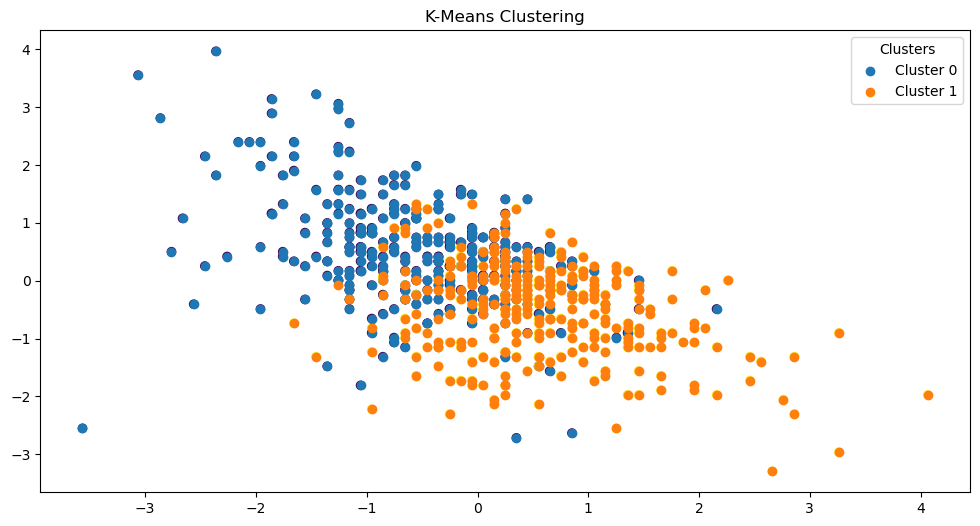

In [23]:
#Visualize the results of cluster analysis
fig, (ax1) = plt.subplots(1, figsize = (12, 6))

scatter = ax1.scatter(scaled_data_all[:, 0], scaled_data_all[:, 1], c = kmeans_labels_all)
ax1.set_title('K-Means Clustering')

#Add the legend
unique_labels = np.unique(kmeans_labels_all)
for label in unique_labels:
    mask = kmeans_labels_all == label
    ax1.scatter(scaled_data_all[mask, 0], scaled_data_all[mask, 1], 
               label = f'Cluster {label}')
ax1.legend(title = 'Clusters')

plt.show()

In [24]:
#Aggregate average features by cluster
kmeans_summary_all = stats_by_player_all.groupby('cluster')[features].mean().round(2)
kmeans_summary_all

,deuce_wide_pct,deuce_t_pct,ad_wide_pct,ad_t_pct
cluster,,,,
0,0.30,0.46,0.55,0.25
1,0.41,0.34,0.40,0.36


**Conclusion**: 
- **Cluster 0**: Strong asymmetry between sides. T-zone serve (46%) dominates on the deuce side (attacking the backhand), wide serve (55%) dominates on the ad side (pushing opponent off the court). Tactic is clear "T/wide" pattern.
- **Cluster 1**: Almost symmetric play on both sides. Moderate preference for wide serves on the deuce and ad sides (41% and 40% respectively). Tactic is adaptive and no extremes.

### Create a function to display specific tennis player's serve statistics

In [25]:
#Display tennis player's serve statistics and cluster characteristics
def player_info(player):
    
    cluster_info = {
        0: 'Strong asymmetry between sides. T-zone serve dominates on the deuce side (attacking the backhand), wide serve dominates on the ad side (pushing opponent off the court)',
        1: 'Almost symmetric play on both sides. Moderate preference for wide serves on the deuce and ad sides'
    }
    
    stats_by_player = stats_by_player_all[stats_by_player_all.player == player]
    if stats_by_player.empty:
        print(f"Player {player} isn't found")
        return
        
    row = stats_by_player.iloc[0]
    cluster_id = row['cluster']
    
    print(f"Player: {row['player']}")
    print(f" ")
    print(f"Hand: {row['hand']}")
    print(f" ")
    print(f"Type: {cluster_info.get(cluster_id, f'Cluster {cluster_id} without description')}")
    print(f" ")
    print(f"Deuce side:")
    print(f"Percentage of wide serve: {row['deuce_wide_pct']}")
    print(f"Percentage of middle serve: {row['deuce_middle_pct']}")
    print(f"Percentage of t serve: {row['deuce_t_pct']}")
    print(f" ")
    print(f"Ad side:")
    print(f"Percentage of wide serve: {row['ad_wide_pct']}")
    print(f"Percentage of middle serve: {row['ad_middle_pct']}")
    print(f"Percentage of t serve: {row['ad_t_pct']}")
    print(f" ")
    print(f"Errors on serve:")
    print(f"Percentage of errors into the net: {row['err_net_pct']}")
    print(f"Percentage of wide serve errors: {row['err_wide_pct']}")
    print(f"Percentage of deep serve errors: {row['err_deep_pct']}")
    print(f"Percentage of wide and deep serve errors: {row['err_wide_deep_pct']}")

In [26]:
#Enter the tennis player's name inside the brackets
player_info('Daniil Medvedev')

Player: Daniil Medvedev
 
Hand: R
 
Type: Almost symmetric play on both sides. Moderate preference for wide serves on the deuce and ad sides
 
Deuce side:
Percentage of wide serve: 0.5
Percentage of middle serve: 0.14
Percentage of t serve: 0.36
 
Ad side:
Percentage of wide serve: 0.47
Percentage of middle serve: 0.14
Percentage of t serve: 0.39
 
Errors on serve:
Percentage of errors into the net: 0.39
Percentage of wide serve errors: 0.18
Percentage of deep serve errors: 0.38
Percentage of wide and deep serve errors: 0.05


In [27]:
player_info('Andrey Rublev')

Player: Andrey Rublev
 
Hand: R
 
Type: Strong asymmetry between sides. T-zone serve dominates on the deuce side (attacking the backhand), wide serve dominates on the ad side (pushing opponent off the court)
 
Deuce side:
Percentage of wide serve: 0.35
Percentage of middle serve: 0.14
Percentage of t serve: 0.51
 
Ad side:
Percentage of wide serve: 0.54
Percentage of middle serve: 0.14
Percentage of t serve: 0.33
 
Errors on serve:
Percentage of errors into the net: 0.53
Percentage of wide serve errors: 0.2
Percentage of deep serve errors: 0.24
Percentage of wide and deep serve errors: 0.02
